# Predictive Maintenance — Machine Failure Detection

**Machine Learning Portfolio Project | Python · Scikit-learn · Imbalanced-learn · Pandas**

## Project Overview

This notebook compares **Isolation Forest** (unsupervised anomaly detection) and **Logistic Regression with RandomOverSampler** (supervised classification) for predicting rare machine failures on the **AI4I 2020 Predictive Maintenance Dataset**.

**Dataset:** 10,000 synthetic machine observations with one categorical feature (`Type`), five numerical operating variables, and a binary target (`Machine failure`). Only **339 observations (3.39%)** represent failures.

**Objectives**
- Perform data-quality checks and prevent target leakage.
- Build a reproducible, stratified **Train / Validation / Test (60/20/20)** workflow.
- Fit preprocessing and oversampling **on Train only**.
- Compare ranking quality (Average Precision, ROC-AUC) and decision quality (precision, recall, F1).
- Select decision thresholds on Validation with a **minimum precision of 90%**.
- Analyze the operational trade-off between false alarms and missed machine failures.

**Conventions:** `0 = normal`, `1 = failure`; **higher anomaly score or predicted probability = greater failure risk**.

> **Scope:** AI4I is a **synthetic** dataset. The notebook transfers *modeling methods*, not pretrained models, from the credit-card-fraud experiment. Both models are fitted anew on AI4I. A random stratified test split does not establish performance under future temporal or equipment drift.

## Setup and Reproducibility

Load the required libraries, identify the repository root, and set `SEED = 42`. Reusable evaluation and visualization helpers are imported from `src/utils.py`.

The notebook is designed to run from the project root or from the `notebooks/` directory. Library versions are printed to help reproduce the experiments.

In [1]:
from pathlib import Path
import sys
import random
import importlib

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
import imblearn

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    balanced_accuracy_score,
    precision_recall_curve,
)
from imblearn.over_sampling import RandomOverSampler

# Resolve the repository root (notebook run from root or notebooks/).
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "utils.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "utils.py").is_file() or not (PROJECT_ROOT / "data").is_dir():
    raise FileNotFoundError("Project folders src/ and data/ were not found.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import utils
importlib.reload(utils)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Project root:", PROJECT_ROOT)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Imbalanced-learn:", imblearn.__version__)


Project root: C:\Users\Lenovo\Desktop\Lyon 1\M2_DS\ML\TP\anomaly_detection_ml
NumPy: 2.3.4
Pandas: 2.3.3
Matplotlib: 3.10.7
Scikit-learn: 1.9.1
SciPy: 1.16.3
Imbalanced-learn: 0.14.2


## 1. Dataset Exploration and Data Quality

### 1.1 Initial Inspection

The **AI4I 2020** dataset contains **10,000 synthetic observations** and records operating measurements, product identifiers, and different failure-related labels. We inspect the dataset dimensions, feature types, sample observations, and descriptive statistics before modeling.

**Source:** [UCI Machine Learning Repository — AI4I 2020](https://archive.ics.uci.edu/dataset/601/ai4i) (DOI: [10.24432/C5HS5C](https://doi.org/10.24432/C5HS5C), **CC BY 4.0**).

In [2]:

# Chargement du dataset

import kagglehub

# Use the local dataset if available
ai4i_path = PROJECT_ROOT / "data" / "ai4i2020.csv"

if not ai4i_path.exists():
    ai4i_path = kagglehub.dataset_download(
        "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
        path="ai4i2020.csv"
    )

df_ai4i = pd.read_csv(ai4i_path)
# Exploration
print("Dimensions :", df_ai4i.shape)

print("\nColonnes :")
print(df_ai4i.columns.tolist())

print("\nPremières observations :")
display(df_ai4i.head())

print("\nTypes des variables :")
print(df_ai4i.dtypes)

print("\nStatistiques descriptives :")
display(df_ai4i.describe())


100%|██████████| 510k/510k [00:00<00:00, 1.21MB/s]

Dimensions : (10000, 14)

Colonnes :
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Premières observations :


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Types des variables :
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Statistiques descriptives :


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### 1.2 Data Quality Checks

We check missing values, exact duplicate rows, duplicates after dropping identifiers, and contradictory target labels for the same operating-feature profile. These checks are descriptive; no records are removed.

In [3]:

# Valeurs manquantes et doublons exacts
missing_ai4i, doublons_ai4i = utils.check_data_quality(df_ai4i)

print("Valeurs manquantes :")
print(missing_ai4i)

print("\nDoublons exacts :", doublons_ai4i)

# Doublons sans identifiants
df_sans_id_ai4i = df_ai4i.drop(
    columns=["UDI", "Product ID"]
)

print(
    "Doublons sans identifiants :",
    df_sans_id_ai4i.duplicated().sum()
)

# Variables de fonctionnement
colonnes_features_ai4i = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Profils identiques avec cibles contradictoires
conflits_ai4i = df_ai4i.groupby(
    colonnes_features_ai4i
)["Machine failure"].nunique()

print(
    "Profils avec cibles contradictoires :",
    (conflits_ai4i > 1).sum()
)


Valeurs manquantes :
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Doublons exacts : 0
Doublons sans identifiants : 0
Profils avec cibles contradictoires : 0


**Observation:** The dataset contains no missing values, exact duplicates, duplicates after excluding product identifiers, or contradictory targets for identical operating-feature profiles. We retain all **10,000 observations**.

These checks do not eliminate every possible source of data leakage or dependence between observations.

### 1.3 Feature Selection and Leakage Prevention

The target is `Machine failure` (`0 = normal`, `1 = failure`). We retain six operating features: `Type`, `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, and `Tool wear [min]`.

We exclude `UDI` and `Product ID` (identifiers), plus `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` (failure-mode indicators related to how the synthetic target is constructed). Including these indicators could leak target information into the model.

In [4]:

# Variable cible
y_ai4i = df_ai4i["Machine failure"]

# Colonnes à exclure
colonnes_exclues_ai4i = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

# Variables explicatives
X_ai4i = df_ai4i.drop(columns=colonnes_exclues_ai4i)

# Vérifications
print("Dimensions de X :", X_ai4i.shape)
print("Dimensions de y :", y_ai4i.shape)

print("\nVariables conservées :")
print(X_ai4i.columns.tolist())

print("\nValeurs manquantes dans X :", X_ai4i.isna().sum().sum())


Dimensions de X : (10000, 6)
Dimensions de y : (10000,)

Variables conservées :
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Valeurs manquantes dans X : 0


## 2. Class Imbalance and Preprocessing

### 2.1 Machine-Failure Frequency

We inspect the distribution of the binary target. Machine failures are rare, so **accuracy alone can be misleading**. We prioritize Average Precision (AP), recall, precision, F1-score, and false-negative counts.

AI4I observations are generated synthetically; they are not measurements collected from an operational maintenance system.

,Effectif,Pourcentage (%)
Normale (0),9661,96.61
Panne (1),339,3.39


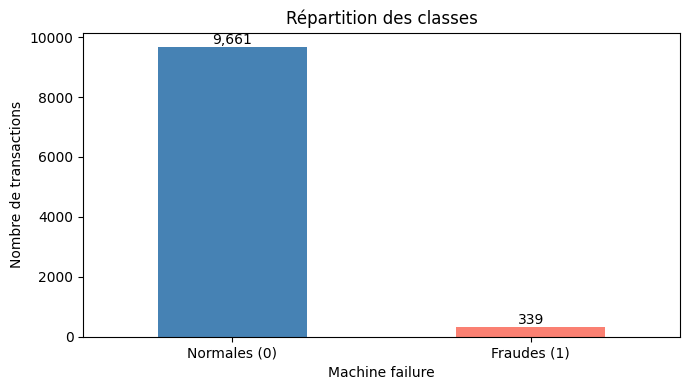

In [5]:

# Distribution des classes
distribution_ai4i = pd.DataFrame({
    "Effectif": y_ai4i.value_counts().sort_index(),
    "Pourcentage (%)": (
        y_ai4i.value_counts(normalize=True).sort_index() * 100
    )
})

distribution_ai4i.index = ["Normale (0)", "Panne (1)"]

display(distribution_ai4i.round(2))

# Visualisation
utils.plot_class_distribution(y_ai4i)


**Observation:** The dataset contains **9,661 normal observations (96.61%)** and **339 failures (3.39%)**. A model that always predicts normal operation would have high accuracy while detecting no machine failures.

This class imbalance motivates careful threshold selection and explicit analysis of missed failures.

### 2.2 Stratified Train / Validation / Test Split

We use a reproducible **60% / 20% / 20%** stratified split (`SEED = 42`):

- **Train:** Fit preprocessing and models; apply any oversampling here only.
- **Validation:** Compare rankings and select decision thresholds.
- **Test:** Assess the frozen models and thresholds once.

We verify that the row indices do not overlap. **Limit:** This is a random stratified split, not a chronological or equipment-grouped evaluation.

In [6]:

# Premier découpage : 60 % Train, 40 % temporaire
X_train_ai4i, X_temp_ai4i, y_train_ai4i, y_temp_ai4i = train_test_split(
    X_ai4i,
    y_ai4i,
    test_size=0.4,
    stratify=y_ai4i,
    random_state=SEED
)

# Deuxième découpage : 20 % Validation, 20 % Test
X_val_ai4i, X_test_ai4i, y_val_ai4i, y_test_ai4i = train_test_split(
    X_temp_ai4i,
    y_temp_ai4i,
    test_size=0.5,
    stratify=y_temp_ai4i,
    random_state=SEED
)

# Vérification des ensembles
for nom, X_part, y_part in [
    ("Train", X_train_ai4i, y_train_ai4i),
    ("Validation", X_val_ai4i, y_val_ai4i),
    ("Test", X_test_ai4i, y_test_ai4i)
]:
    print(
        f"{nom} : {X_part.shape[0]} observations | "
        f"Pannes : {y_part.sum()} | "
        f"Taux : {y_part.mean() * 100:.2f} %"
    )

# Vérification de l'absence de chevauchement d'indices
print("\nChevauchements :")
print("Train / Validation :", len(X_train_ai4i.index.intersection(X_val_ai4i.index)))
print("Train / Test :", len(X_train_ai4i.index.intersection(X_test_ai4i.index)))
print("Validation / Test :", len(X_val_ai4i.index.intersection(X_test_ai4i.index)))


Train : 6000 observations | Pannes : 203 | Taux : 3.38 %
Validation : 2000 observations | Pannes : 68 | Taux : 3.40 %
Test : 2000 observations | Pannes : 68 | Taux : 3.40 %

Chevauchements :
Train / Validation : 0
Train / Test : 0
Validation / Test : 0


### 2.3 Train-Only Feature Preprocessing

We use a `ColumnTransformer` with:

- `StandardScaler` for the **five numerical operating features**.
- `OneHotEncoder(handle_unknown="ignore")` for the categorical variable `Type`.

The transformer is **fitted exclusively on Train** and then reused unchanged for Validation and Test. This protects the evaluation against preprocessing leakage.

In [7]:

# Identification des variables
colonnes_numeriques_ai4i = X_train_ai4i.select_dtypes(
    include="number"
).columns.tolist()

colonnes_categorielles_ai4i = ["Type"]

# Prétraitement
preprocessor_ai4i = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        colonnes_numeriques_ai4i
    ),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        colonnes_categorielles_ai4i
    )
])

# Ajustement uniquement sur Train
X_train_ai4i_prep = preprocessor_ai4i.fit_transform(
    X_train_ai4i
)

# Transformation sans réajustement
X_val_ai4i_prep = preprocessor_ai4i.transform(
    X_val_ai4i
)

X_test_ai4i_prep = preprocessor_ai4i.transform(
    X_test_ai4i
)

# Vérifications
print("Variables numériques :", colonnes_numeriques_ai4i)
print("Variables catégorielles :", colonnes_categorielles_ai4i)

print("\nDimensions après prétraitement :")
print("Train :", X_train_ai4i_prep.shape)
print("Validation :", X_val_ai4i_prep.shape)
print("Test :", X_test_ai4i_prep.shape)

print("\nVariables après transformation :")
print(preprocessor_ai4i.get_feature_names_out())


Variables numériques : ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Variables catégorielles : ['Type']

Dimensions après prétraitement :
Train : (6000, 8)
Validation : (2000, 8)
Test : (2000, 8)

Variables après transformation :
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


## 3. Comparing Anomaly Detection and Supervised Classification

### 3.1 Isolation Forest — Unsupervised Detection

Isolation Forest is fitted to the preprocessed Train features **without target labels**. We use `contamination="auto"` and a fixed random seed. Continuous anomaly scores are calculated on Validation, with **higher scores meaning more anomalous observations**.

We also record fitting and scoring times. The model is fitted **from scratch on AI4I**; no parameters from the credit-card dataset are transferred.

In [8]:

# Initialisation
iforest_ai4i = IsolationForest(
    contamination="auto",
    random_state=SEED
)

# Apprentissage sur Train
iforest_ai4i, temps_fit_if_ai4i = utils.fit_model(
    iforest_ai4i,
    X_train_ai4i_prep
)

# Calcul des scores sur Validation
scores_val_if_ai4i, temps_score_if_ai4i = (
    utils.compute_anomaly_scores(
        iforest_ai4i,
        X_val_ai4i_prep
    )
)

# Résultats
print(f"IF | Fit : {temps_fit_if_ai4i:.4f} s")
print(f"IF | Score : {temps_score_if_ai4i:.4f} s")

print(
    f"Scores min/max : "
    f"{np.min(scores_val_if_ai4i):.4f} / "
    f"{np.max(scores_val_if_ai4i):.4f}"
)

print("Nombre de scores :", len(scores_val_if_ai4i))


IF | Fit : 0.1946 s
IF | Score : 0.0222 s
Scores min/max : 0.3931 / 0.6926
Nombre de scores : 2000


### 3.2 Logistic Regression with Random Oversampling

The supervised baseline uses **Logistic Regression (`C=1.0`)** and `RandomOverSampler` to balance the two classes in **Train only**.

The model is fitted on the resampled training data. We then compute its predicted failure probabilities on the original, imbalanced Validation set and record both fitting and scoring times.

Random oversampling does **not** change Validation or Test.

In [9]:

# Rééquilibrage uniquement sur Train
ros_ai4i = RandomOverSampler(random_state=SEED)

X_train_ai4i_ros, y_train_ai4i_ros = ros_ai4i.fit_resample(
    X_train_ai4i_prep,
    y_train_ai4i
)

# Initialisation de la régression logistique
logreg_ai4i = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=SEED
)

# Apprentissage
logreg_ai4i, temps_fit_logreg_ai4i = utils.fit_model(
    logreg_ai4i,
    X_train_ai4i_ros,
    y_train_ai4i_ros
)

# Scores sur Validation
scores_val_logreg_ai4i, temps_score_logreg_ai4i = (
    utils.compute_supervised_scores(
        logreg_ai4i,
        X_val_ai4i_prep
    )
)

# Vérifications
print("Train avant ROS :", X_train_ai4i_prep.shape)
print("Train après ROS :", X_train_ai4i_ros.shape)

print("\nRépartition après ROS :")
print(pd.Series(y_train_ai4i_ros).value_counts().sort_index())

print(f"\nLogReg | Fit : {temps_fit_logreg_ai4i:.4f} s")
print(f"LogReg | Score : {temps_score_logreg_ai4i:.4f} s")

print(
    f"Scores min/max : "
    f"{np.min(scores_val_logreg_ai4i):.4f} / "
    f"{np.max(scores_val_logreg_ai4i):.4f}"
)

print("Nombre de scores :", len(scores_val_logreg_ai4i))


Train avant ROS : (6000, 8)
Train après ROS : (11594, 8)

Répartition après ROS :
Machine failure
0    5797
1    5797
Name: count, dtype: int64

LogReg | Fit : 0.0768 s
LogReg | Score : 0.0005 s
Scores min/max : 0.0010 / 0.9981
Nombre de scores : 2000


**Observation:** Random oversampling increases the training set from **6,000** to **11,594** records, with **5,797 observations in each class**. Validation and Test retain their natural failure prevalence.

Training and scoring times depend on the hardware and library versions, so the measured values are not universal speed benchmarks.

## 4. Model Evaluation and Decision Thresholds

### 4.1 Ranking Performance on Validation

We compare the **continuous** scores of both models using:

- **Average Precision (AP):** Summarizes precision–recall ranking, especially relevant for rare failures.
- **ROC-AUC:** Assesses how well a model ranks failures above normal observations.

These metrics do not require a binary decision threshold. The ROC and precision–recall curves provide complementary views of ranking quality.

,Méthode,AP,ROC-AUC
0,Isolation Forest,0.1176,0.7501
1,Régression logistique (ROS),0.4068,0.8828


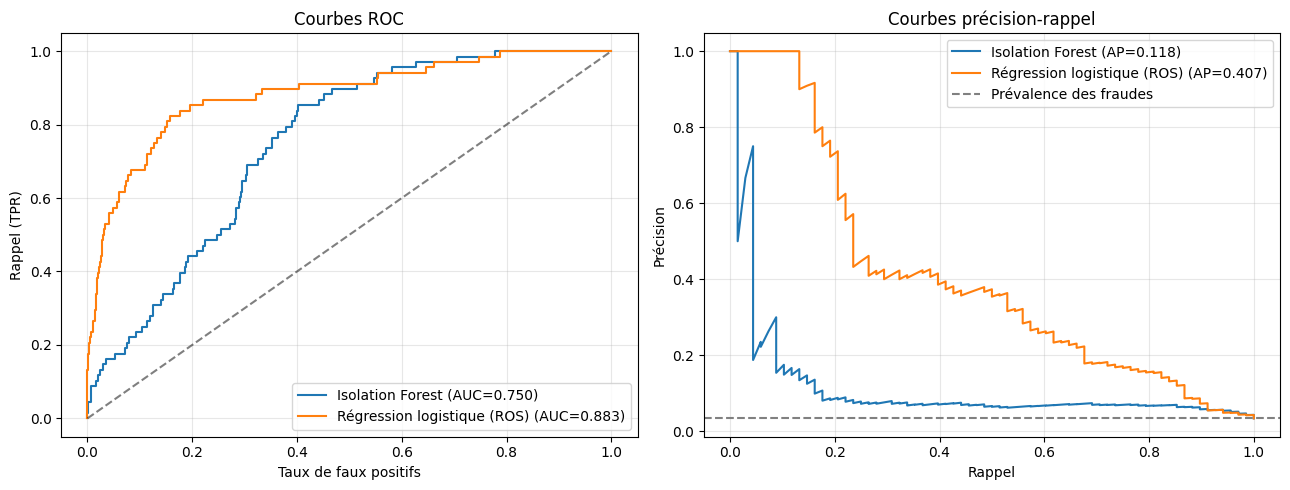

In [10]:
# Évaluation d'Isolation Forest
ap_if_ai4i, auc_if_ai4i = utils.evaluate_scores(
    y_val_ai4i,
    scores_val_if_ai4i
)

# Évaluation de la régression logistique
ap_logreg_ai4i, auc_logreg_ai4i = utils.evaluate_scores(
    y_val_ai4i,
    scores_val_logreg_ai4i
)

# Tableau comparatif
df_scores_ai4i = pd.DataFrame([
    {
        "Méthode": "Isolation Forest",
        "AP": ap_if_ai4i,
        "ROC-AUC": auc_if_ai4i
    },
    {
        "Méthode": "Régression logistique (ROS)",
        "AP": ap_logreg_ai4i,
        "ROC-AUC": auc_logreg_ai4i
    }
])

display(df_scores_ai4i.round(4))

# Courbes ROC et précision-rappel sur Validation
utils.plot_roc_pr_curves(
    y_val_ai4i,
    {
        "Isolation Forest": scores_val_if_ai4i,
        "Régression logistique (ROS)": scores_val_logreg_ai4i
    }
)

**Observation:** On Validation, Logistic Regression with ROS ranks machine failures more effectively than Isolation Forest:

| Model | AP | ROC-AUC |
|---|---:|---:|
| Logistic Regression (ROS) | **0.4068** | **0.8828** |
| Isolation Forest | 0.1176 | 0.7501 |

Good ranking scores do **not** guarantee high recall at a stringent operating precision requirement; a separate threshold analysis follows.

### 4.2 Threshold Selection on Validation

For each model, we seek the threshold that **maximizes recall subject to at least 90% precision** on Validation.

If no positive-alert threshold satisfies the constraint, we retain the **best-F1 threshold for exploratory comparison only**, and label that model *not admissible*. We report precision, recall, F1, balanced accuracy, and alert counts.

**No threshold is selected using Test.** The exact threshold values are preserved for final predictions.

In [11]:

# Scores des deux modèles sur Validation
scores_modeles_ai4i = {
    "Isolation Forest": scores_val_if_ai4i,
    "Régression logistique (ROS)": scores_val_logreg_ai4i
}

resultats_seuils_ai4i = []
seuils_optimaux_ai4i = {}

for nom, scores in scores_modeles_ai4i.items():

    scores = np.asarray(scores)

    # Recherche du seuil sous contrainte
    resultat = utils.select_threshold(
        y_val_ai4i,
        scores,
        min_precision=0.90
    )

    if resultat is not None:
        seuil = resultat["Seuil"]
        statut = "Admissible"

    else:
        # Seuil exploratoire maximisant le F1
        precision_c, rappel_c, seuils_c = precision_recall_curve(
            y_val_ai4i,
            scores
        )

        p = precision_c[:-1]
        r = rappel_c[:-1]

        f1_c = np.divide(
            2 * p * r,
            p + r,
            out=np.zeros_like(p),
            where=(p + r) > 0
        )

        seuil = seuils_c[np.argmax(f1_c)]
        statut = "Non admissible"

    # Conservation du seuil exact
    seuils_optimaux_ai4i[nom] = (
        seuil if statut == "Admissible" else None
    )

    # Prédictions sur Validation
    y_pred = (scores >= seuil).astype(int)

    # Évaluation
    evaluation = utils.evaluate_anomalies(
        y_val_ai4i,
        y_pred
    )

    resultats_seuils_ai4i.append({
        "Méthode": nom,
        "Statut": statut,
        "Seuil": seuil,
        "Précision": precision_score(
            y_val_ai4i, y_pred, zero_division=0
        ),
        "Rappel": recall_score(
            y_val_ai4i, y_pred, zero_division=0
        ),
        "F1": evaluation["F1"],
        "Balanced accuracy": balanced_accuracy_score(
            y_val_ai4i, y_pred
        ),
        "Alertes": int(y_pred.sum()),
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "TP": evaluation["TP"]
    })

# Tableau comparatif
df_seuils_ai4i = pd.DataFrame(resultats_seuils_ai4i)

display(
    df_seuils_ai4i.style.format({
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}",
        "Balanced accuracy": "{:.4f}"
    })
)


,Méthode,Statut,Seuil,Précision,Rappel,F1,Balanced accuracy,Alertes,FP,FN,TP
0,Isolation Forest,Admissible,0.692592232291,1.0000,0.0147,0.0290,0.5074,1,0,67,1
1,Régression logistique (ROS),Admissible,0.980199845086,0.9167,0.1618,0.2750,0.5806,12,1,57,11


### 4.3 Final Evaluation on Held-Out Test Data

We score the **2,000 test observations**, containing **68 machine failures**, using the models fitted on Train and the decision thresholds selected on Validation. There is **no retraining or retuning on Test**.

We report AP, ROC-AUC, precision, recall, F1-score, balanced accuracy, false positives, false negatives, and execution time. In maintenance, missed failures (false negatives) deserve particular attention.

In [12]:

# Modèles déjà entraînés et leurs données de Test
modeles_test_ai4i = [
    (
        "Isolation Forest",
        iforest_ai4i,
        temps_fit_if_ai4i
    ),
    (
        "Régression logistique (ROS)",
        logreg_ai4i,
        temps_fit_logreg_ai4i
    )
]

resultats_test_ai4i = []
scores_test_ai4i = {}

for nom, modele, temps_fit in modeles_test_ai4i:

    # Calcul des scores sur Test
    if nom == "Isolation Forest":
        scores, temps_score = utils.compute_anomaly_scores(
            modele,
            X_test_ai4i_prep
        )
    else:
        scores, temps_score = utils.compute_supervised_scores(
            modele,
            X_test_ai4i_prep
        )

    scores_test_ai4i[nom] = scores

    # Seuil figé sur Validation
    seuil = seuils_optimaux_ai4i[nom]

    # Prédictions
    y_pred = (np.asarray(scores) >= seuil).astype(int)

    # Métriques de classement
    ap, auc = utils.evaluate_scores(
        y_test_ai4i,
        scores
    )

    # Métriques des prédictions
    evaluation = utils.evaluate_anomalies(
        y_test_ai4i,
        y_pred
    )

    resultats_test_ai4i.append({
        "Méthode": nom,
        "AP": ap,
        "ROC-AUC": auc,
        "Seuil": seuil,
        "Précision": precision_score(
            y_test_ai4i, y_pred, zero_division=0
        ),
        "Rappel": recall_score(
            y_test_ai4i, y_pred, zero_division=0
        ),
        "F1": evaluation["F1"],
        "Balanced accuracy": balanced_accuracy_score(
            y_test_ai4i, y_pred
        ),
        "Alertes": int(y_pred.sum()),
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "TP": evaluation["TP"],
        "Temps fit (s)": temps_fit,
        "Temps score (s)": temps_score
    })

# Tableau comparatif final
df_test_ai4i = pd.DataFrame(resultats_test_ai4i)

display(
    df_test_ai4i.style.format({
        "AP": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}",
        "Balanced accuracy": "{:.4f}",
        "Temps fit (s)": "{:.4f}",
        "Temps score (s)": "{:.4f}"
    })
)


,Méthode,AP,ROC-AUC,Seuil,Précision,Rappel,F1,Balanced accuracy,Alertes,FP,FN,TP,Temps fit (s),Temps score (s)
0,Isolation Forest,0.0743,0.7086,0.692592232291,0.0000,0.0000,0.0000,0.5000,0,0,68,0,0.1946,0.0313
1,Régression logistique (ROS),0.4025,0.9041,0.980199845086,1.0000,0.0441,0.0845,0.5221,3,0,65,3,0.0768,0.0004


**Observation — Held-Out Test:**

- **Isolation Forest:** Produces **zero alerts** and misses all **68 failures**. Precision is mathematically **undefined when there are no positive predictions**; the evaluation code displays `0` by convention.
- **Logistic Regression with ROS:** Produces **3 alerts**, all correct (**3 TP, 0 FP**), but misses **65 of 68 failures**. Its precision is **100% on just three alerts**, while its recall is only **4.41%**.

Logistic Regression has the better test ranking (**AP = 0.4025**, **ROC-AUC = 0.9041**), but the high-precision operating point suppresses most actual failures.

**Operational interpretation:** Neither configuration achieves useful recall for preventative maintenance under the current **≥90% precision** requirement. The tiny alert count makes the observed perfect precision highly uncertain.

## 5. Discussion and Limitations

### 5.1 Cross-Domain Comparison

The earlier **Credit Card Fraud** task contained approximately **0.17% fraud**, whereas AI4I contains **3.39% machine failures**. Anomalies differ in their generation, prevalence, and feature structure; **AP values from different datasets should not be compared as if their baselines were identical**.

The models here are **retrained on AI4I**. The transferable component is the evaluation protocol: data preparation, class-imbalance handling, validation-based threshold selection, and held-out assessment—not the learned model parameters.

### 5.2 Methodological Limitations

- **Synthetic data:** AI4I mimics industrial conditions but does not validate performance in an operating plant.
- **Random split:** No chronological or machine-level generalization test is performed.
- **Limited model selection:** Only one configuration of each algorithm is evaluated in this transfer study.
- **High precision requirement:** The ≥90% constraint results in extremely few alerts and very low failure recall.
- **Rare test events:** Precision = 100% from just three positive predictions is not robust evidence of operational precision.

## 6. Conclusion

**Logistic Regression with RandomOverSampler outperforms Isolation Forest on failure ranking**, but its test recall is only **4.41%** under the selected precision-constrained threshold. Isolation Forest produces no alerts at its selected operating point.

This comparison illustrates the gap between **ranking metrics** and **operational decisions**. The current models are an educational benchmark, **not a deployable predictive-maintenance alarm system**. Future experiments could investigate additional algorithms, class-weighting, cost-sensitive thresholds, and chronological or equipment-wise validation.

In [13]:

output_dir = PROJECT_ROOT / "results" / "predictive_maintenance"
output_dir.mkdir(parents=True, exist_ok=True)

df_scores_ai4i.to_csv(
    output_dir / "validation_scores.csv", index=False
)

df_test_ai4i.to_csv(
    output_dir / "final_test_results.csv", index=False
)


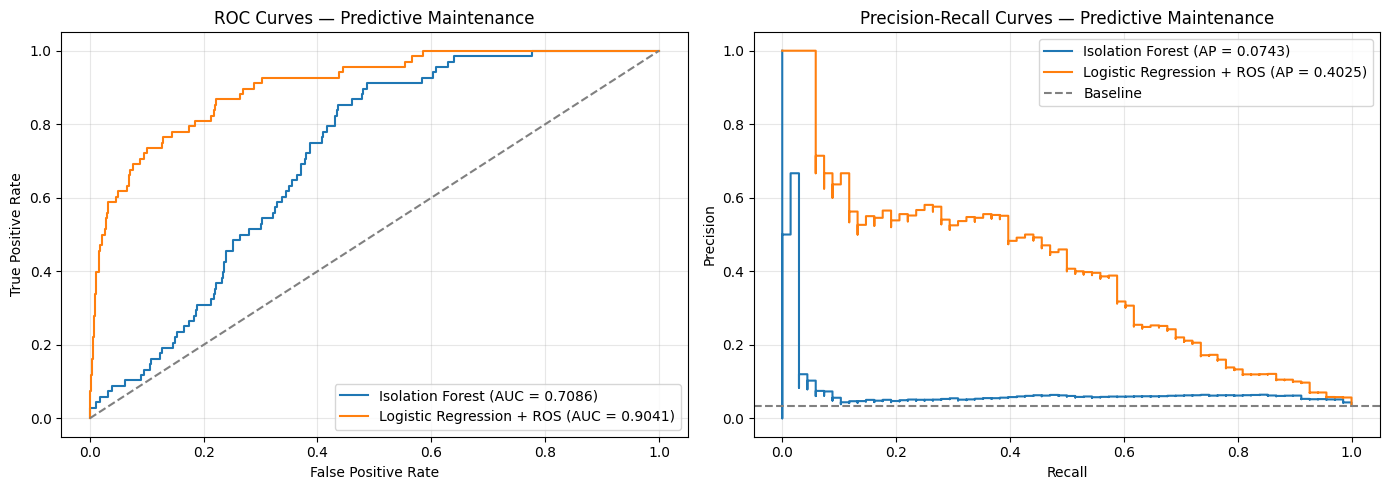

In [14]:

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Final test scores from both models
models_scores = {
    "Isolation Forest": scores_test_ai4i["Isolation Forest"],
    "Logistic Regression + ROS": scores_test_ai4i[
        "Régression logistique (ROS)"
    ]
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, scores in models_scores.items():

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test_ai4i, scores)
    auc = roc_auc_score(y_test_ai4i, scores)

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        y_test_ai4i, scores
    )

    ap = average_precision_score(y_test_ai4i, scores)

    axes[1].step(
        recall, precision,
        where="post",
        label=f"{name} (AP = {ap:.4f})"
    )

# ROC formatting
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

axes[0].set_title("ROC Curves — Predictive Maintenance")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall formatting
axes[1].axhline(
    y_test_ai4i.mean(),
    color="gray",
    linestyle="--",
    label="Baseline"
)

axes[1].set_title("Precision-Recall Curves — Predictive Maintenance")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Export
figure_dir = PROJECT_ROOT / "figures" / "predictive_maintenance"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "model_comparison_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



### Model Performance Visualization

The ROC and Precision-Recall curves compare Isolation Forest and Logistic Regression with RandomOverSampler on the held-out test set.

Logistic Regression achieves better ranking performance, with an Average Precision of 0.4025 and a ROC-AUC of 0.9041.

However, under the precision-constrained decision threshold selected on validation, the model detects only 3 out of 68 failures.

This highlights the difference between ranking performance and operational detection performance, particularly when high precision is required.
